In [2]:
import sys
sys.path.append("../")

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import expm
from qiskit.quantum_info import Statevector, SparsePauliOp
from qitp.engine.unitary_approximation import UnitaryApproximation
from qitp.engine.propagation import QITEPropagation
from qitp.engine.cqite_run import run_qite
from qitp.engine.prepare_state import constraint_rotation, prepare_state
from qitp.simulation.backend import SimulatorBackend

In [4]:
from qitp.ansatz.pauli_basis import (
    PauliBasis
)
from qitp.ansatz.commutator_basis import (
    CommutatorBasis
)

In [5]:
from qiskit.quantum_info import SparsePauliOp

h = 1.0
J = 1.0

H = SparsePauliOp(
    [
        "XII",
        "IXI",
        "IIX",
        "ZZI",
        "ZIZ",
        "IZZ",
    ],
    coeffs=[h, h, h, J, J, J]
)

In [6]:
Mz = constraints = [
    SparsePauliOp(["ZII"], coeffs=[1.0]),
    SparsePauliOp(["IZI"], coeffs=[1.0]),
    SparsePauliOp(["IIZ"], coeffs=[1.0]),
]

Identity = SparsePauliOp(["III"],coeffs=[1.0])

In [7]:
seeds = [
    SparsePauliOp("ZII"),
    SparsePauliOp("IZI"),
    SparsePauliOp("IIZ")
]

In [137]:
H_eff = H + sum(Mz[1:], start=Mz[0]) + Identity

In [139]:
basis = CommutatorBasis.from_seed(hamiltonian=H_eff, seeds=seeds, depth=7)

In [141]:
dt=1e-2
nsteps=100
target=0.5

energies=[]
fidelities=[]
errors=[]
magnetizations=[]

In [163]:
rotations = []

for constraint in Mz:

    rotations.append(
        constraint_rotation(
            constraint,
            target
        )
    )

In [165]:
circuit = prepare_state(
    3,
    rotations
)

In [167]:
circuit = circuit.decompose()

In [169]:
approx = UnitaryApproximation(basis)

backend = SimulatorBackend()

prop = QITEPropagation(
    H,
    approx,
    backend,
    seeds,
    depth=7
)

prop.constraints = [
    Identity]
prop.constraints.extend(Mz)

In [171]:
beta0 = prop.compute_betas(
    circuit,
    backend
)

H_eff = H.copy()

for b, C in zip(beta0, Mz):
    H_eff += b * C

In [173]:
from qiskit.quantum_info import Statevector

psi = Statevector.from_instruction(circuit)

In [175]:
results = run_qite(
    prop,
    circuit,
    H,
    Mz,
    dt,
    nsteps,
    state=psi #Remove for exponential advantage
)

energies = results["energies"]
magnetizations = results["magnetizations"] #[np.sum(m) for m in results["magnetizations"]]

In [176]:
print(np.round(energies[-1],3))

-2.191


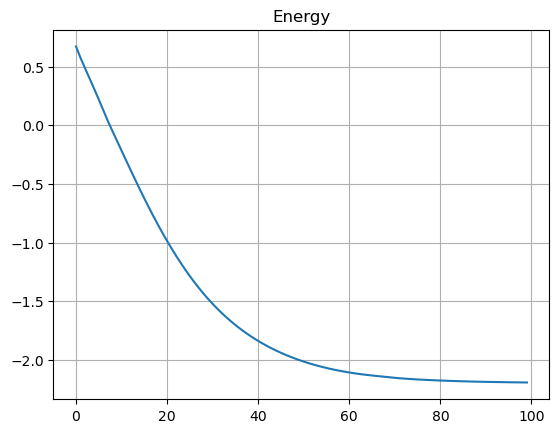

In [177]:
plt.plot(energies); plt.title('Energy'); plt.grid(); plt.show()

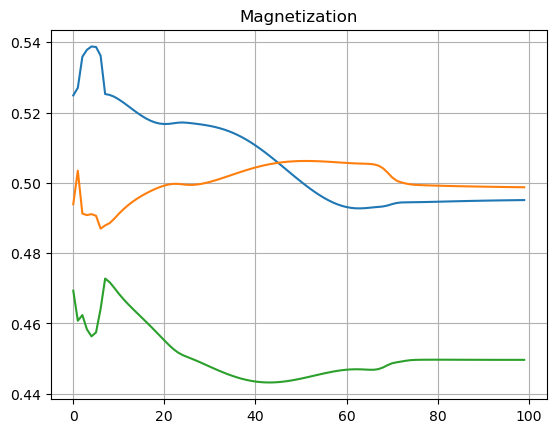

In [178]:
plt.plot(magnetizations); plt.title("Magnetization"); plt.grid(); plt.show()

In [43]:
evals = np.linalg.eigvalsh(
    H.to_matrix()
)

print("Exact spectrum")

print(np.round(evals,2))

Exact spectrum
[-3.46 -2.   -2.   -0.   -0.    0.    3.46  4.  ]


In [45]:
import numpy as np
from scipy.optimize import root

Hm = H.to_matrix()

C = [
    SparsePauliOp(["ZII"], coeffs=[1.0]).to_matrix(),
    SparsePauliOp(["IZI"], coeffs=[1.0]).to_matrix(),
    SparsePauliOp(["IIZ"], coeffs=[1.0]).to_matrix(),
]


def constraints_of_lambda(lmbda):

    H_eff = Hm.copy()

    for a, Ck in zip(lmbda, C):
        H_eff += a * Ck

    eigvals, eigvecs = np.linalg.eigh(H_eff)

    psi = eigvecs[:, 0]

    return np.array([
        np.real(
            np.vdot(
                psi,
                Ck @ psi
            )
        ) - target
        for Ck in C
    ])

sol = root(
    constraints_of_lambda,
    x0=np.zeros(3)
)

print("lambdas =", sol.x)

H_eff = Hm.copy()

for a, Ck in zip(sol.x, C):
    H_eff += a * Ck

eigvals, eigvecs = np.linalg.eigh(H_eff)

psi = eigvecs[:, 0]

energy = np.real(
    np.vdot(
        psi,
        Hm @ psi
    )
)

print("Constrained energy =", energy)

for i, Ck in enumerate(C):
    print(
        f"constraint {i}",
        np.real(
            np.vdot(
                psi,
                Ck @ psi
            )
        )
    )

lambdas = [-1.85366458 -1.85366458 -1.85366458]
Constrained energy = -2.0954941490540886
constraint 0 0.5000000000000028
constraint 1 0.5000000004101594
constraint 2 0.49999999958984803
